# Ballon d'Or — who finishes on the podium?

**Problem.** Every year, a jury of journalists ranks the best ~30 players. We want to predict,
from a player's season (club stats, national-team goals, trophies, market value...), whether he
finishes in the **top 3** of the Ballon d'Or.

**Target:** `top3` (1 if the final rank is 1, 2 or 3, else 0) — a binary classification problem.

**Data:** `data/dataset.csv`, one row per ranked player and per edition (2013–2026).
See `data/README.md` for the sources and the meaning of each column.

This notebook covers the first part of the project:
1. Data overview and cleaning
2. Feature engineering
3. Exploratory data analysis (EDA)
4. Feature importance analysis

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/dataset.csv")
df.shape

(369, 52)

## 2. Data overview

First look at the table: column types, a few rows, summary statistics.

In [3]:
df.head()

,year,rank,name,age,country,position,club,points,trophies_league,trophies_ucl,trophies_uel,trophies_world_cup,trophies_euro,trophies_copa_america,trophies_afcon,trophies_cup,trophies_total,ucl_stage,intl_stage,vote_share,top3,winner,season_based,prev_rank,player_id,apps,minutes,goals,assists,yellow_cards,red_cards,cup_assists,europe_assists,league_assists,cup_goals,europe_goals,league_goals,cup_minutes,europe_minutes,league_minutes,cup_apps,europe_apps,league_apps,ucl_apps,ucl_minutes,ucl_goals,ucl_assists,market_value_eur,intl_goals,intl_major_goals,tm_matched,stats_complete
0,2013,1,Cristiano Ronaldo,28,Portugal,forward,Real Madrid,27.990,0.000,0,0,0,0,0,0,0.000,0.000,4.000,0.000,0.280,1,1,0,2.000,8198.000,47.000,3948.000,57.000,16.000,10.000,1.000,1.000,2.000,13.000,6.000,14.000,37.000,565.000,900.000,2483.000,6.000,10.000,31.000,10.000,900.000,14.000,2.000,100000000.000,7.000,0.000,1,1
1,2013,2,Lionel Messi,26,Argentina,forward,Barcelona,24.720,1.000,0,0,0,0,0,0,1.000,2.000,4.000,0.000,0.247,1,0,0,1.000,28003.000,40.000,3018.000,39.000,12.000,1.000,0.000,1.000,0.000,11.000,2.000,9.000,28.000,353.000,613.000,1917.000,4.000,8.000,26.000,8.000,613.000,9.000,0.000,120000000.000,3.000,0.000,1,1
2,2013,3,Franck Ribéry,30,France,forward,Bayern Munich,23.360,1.000,1,0,0,0,0,0,1.000,4.000,6.000,0.000,0.234,1,0,0,NaN,22068.000,39.000,3021.000,15.000,18.000,5.000,0.000,0.000,3.000,15.000,1.000,4.000,10.000,118.000,951.000,1952.000,2.000,11.000,26.000,10.000,831.000,3.000,3.000,42000000.000,4.000,0.000,1,1
3,2013,4,Zlatan Ibrahimović,32,Sweden,forward,Paris Saint-Germain,5.290,2.000,0,0,0,0,0,0,1.000,3.000,3.000,0.000,0.053,0,0,0,10.000,3455.000,40.000,3433.000,30.000,13.000,8.000,1.000,0.000,2.000,10.000,0.000,9.000,21.000,0.000,708.000,2635.000,0.000,8.000,31.000,8.000,708.000,9.000,2.000,30000000.000,6.000,0.000,1,1
4,2013,5,Neymar,21,Brazil,midfielder,Barcelona,3.170,0.000,0,0,0,0,0,0,1.000,2.000,NaN,0.000,0.032,0,0,0,13.000,68290.000,19.000,1436.000,5.000,11.000,5.000,0.000,0.000,3.000,8.000,0.000,0.000,4.000,0.000,418.000,897.000,0.000,5.000,12.000,5.000,418.000,0.000,3.000,50000000.000,0.000,0.000,1,1


In [4]:
df.dtypes.value_counts()

float64    34
int64      14
str         4
Name: count, dtype: int64

In [5]:
# Number of ranked players and of podium places per edition
df.groupby("year").agg(players=("name", "size"), podium=("top3", "sum"))

,players,podium
year,,
2013,23,3
2014,23,3
2015,23,3
2016,30,3
2017,30,3
2018,30,3
2019,30,3
2021,30,3
2022,30,3


Each edition has exactly 3 podium players, but not the same number of ranked players
(23 in 2013–2015, about 30 afterwards). The positive class is therefore rare: about 1 row out of 10.

In [6]:
# Missing values: count and share, only for columns that have some
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "share": missing / len(df)}).query("missing > 0") \
  .sort_values("missing", ascending=False)

,missing,share
prev_rank,201,0.545
ucl_stage,76,0.206
intl_stage,21,0.057
trophies_league,10,0.027
trophies_total,10,0.027
apps,6,0.016
red_cards,6,0.016
minutes,6,0.016
goals,6,0.016
assists,6,0.016


Three kinds of missing values, each with its own meaning:
- **`prev_rank`** is empty when the player was **not ranked** at the previous edition. This is
  information, not an error: we will turn it into a flag.
- **Club stats** (`apps`, `minutes`, `goals`...) are empty for the 5–6 rows with
  `stats_complete = 0` (league not covered, or known Transfermarkt error).
- **`ucl_stage` / `intl_stage`** are empty when the source did not know the stage reached.

In [7]:
# Summary statistics of the main numeric variables
main_cols = ["age", "minutes", "goals", "assists", "intl_goals", "intl_major_goals",
             "market_value_eur", "trophies_total", "ucl_stage", "intl_stage", "prev_rank"]
df[main_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,369.000,27.496,4.029,17.000,25.000,27.000,30.000,39.000
minutes,363.000,3290.705,709.852,752.000,2821.500,3296.000,3803.500,4770.000
goals,363.000,15.868,13.529,0.000,4.000,13.000,25.000,58.000
assists,363.000,8.581,6.385,0.000,4.000,8.000,12.000,30.000
intl_goals,369.000,2.407,2.886,0.000,0.000,1.000,3.000,19.000
intl_major_goals,369.000,0.835,1.596,0.000,0.000,0.000,1.000,10.000
market_value_eur,368.000,72807065.217,44133121.683,1500000.000,40000000.000,70000000.000,90000000.000,200000000.000
trophies_total,359.000,1.894,1.406,0.000,1.000,2.000,3.000,6.000
ucl_stage,293.000,3.696,1.995,0.000,2.000,4.000,6.000,6.000
intl_stage,348.000,1.928,2.318,0.000,0.000,0.000,4.000,6.000


## 3. Cleaning and feature engineering

### 3.1 Columns we must not use as features (data leakage)

`rank`, `points`, `vote_share` and `winner` are **results of the vote**: they directly give
away the target. Keeping them would produce a perfect but useless model. `player_id`,
`tm_matched`, `name` and `club` are identifiers, not features.

In [8]:
LEAKAGE = ["rank", "points", "vote_share", "winner"]
IDENTIFIERS = ["name", "club", "player_id", "tm_matched"]
TARGET = "top3"

### 3.2 Handling missing values

- `prev_rank` → `ranked_prev` (0/1 flag) and `prev_rank_filled` (31 = "not ranked", i.e. worse
  than the last place).
- Missing trophy counts → 0 (no trophy recorded).
- Missing stages → kept as `NaN` for now (the models step will decide how to impute them).

In [9]:
data = df.copy()

data["ranked_prev"] = data["prev_rank"].notna().astype(int)
data["prev_rank_filled"] = data["prev_rank"].fillna(31)
data["prev_top3"] = (data["prev_rank_filled"] <= 3).astype(int)

trophy_cols = [c for c in data.columns if c.startswith("trophies_")]
data[trophy_cols] = data[trophy_cols].fillna(0)

### 3.3 New features

Raw totals depend on playing time, so we add **per-90-minutes** rates. We also add
"big title" flags, since the vote is known to reward trophies.

In [10]:
data["goal_contrib"] = data["goals"] + data["assists"]            # goals + assists
per90 = 90 / data["minutes"].where(data["minutes"] > 0)          # NaN if no minutes
data["goals_per90"] = data["goals"] * per90
data["goal_contrib_per90"] = data["goal_contrib"] * per90
data["market_value_m"] = data["market_value_eur"] / 1e6          # in millions of euros

data["won_ucl"] = (data["trophies_ucl"] > 0).astype(int)
data["won_major_intl"] = (data[["trophies_world_cup", "trophies_euro", "trophies_copa_america",
                                "trophies_afcon"]].sum(axis=1) > 0).astype(int)
data["won_big_title"] = (data["won_ucl"] | data["won_major_intl"]).astype(int)

### 3.4 Relative features (within an edition)

The Ballon d'Or is a **comparison between the players of the same year**: 30 goals can be
a lot one year and average the next. So for a few key variables we compute the player's
percentile **within his edition** (1.0 = best of the year).

In [11]:
for col in ["goal_contrib", "intl_goals", "market_value_m", "trophies_total"]:
    data[f"{col}_pct_year"] = data.groupby("year")[col].rank(pct=True)

## 4. Target analysis

In [12]:
print(f"Share of podium rows: {data[TARGET].mean():.1%}")
data[TARGET].value_counts()

Share of podium rows: 10.6%


top3
0    330
1     39
Name: count, dtype: int64

The classes are **imbalanced** (≈ 11 % positives). Accuracy will therefore be a misleading
metric: a model predicting "never on the podium" would already reach 89 %. We will use
**ROC AUC** (and check how often the true podium is in the predicted top 3).

## 5. Mean profile: podium vs the rest

Classic first step: compare the **average** (and median) of each variable between the two groups.

In [13]:
compare_cols = ["age", "minutes", "goals", "assists", "goal_contrib", "goal_contrib_per90",
                "intl_goals", "intl_major_goals", "market_value_m", "trophies_total",
                "won_ucl", "won_major_intl", "ucl_stage", "intl_stage", "ranked_prev",
                "prev_top3"]
profile = data.groupby(TARGET)[compare_cols].mean().T
profile.columns = ["rest (top3=0)", "podium (top3=1)"]
profile["ratio"] = profile["podium (top3=1)"] / profile["rest (top3=0)"]
profile.sort_values("ratio", ascending=False)

,rest (top3=0),podium (top3=1),ratio
prev_top3,0.052,0.359,6.968
intl_major_goals,0.694,2.026,2.919
goals,14.068,30.821,2.191
intl_goals,2.148,4.590,2.136
ranked_prev,0.412,0.821,1.991
won_ucl,0.209,0.410,1.962
goal_contrib,22.176,43.333,1.954
won_major_intl,0.124,0.231,1.857
goal_contrib_per90,0.624,1.068,1.711
market_value_m,68.574,108.513,1.582


In [14]:
# Medians are more robust to extreme values (e.g. a 61-goal season)
data.groupby(TARGET)[["goals", "goal_contrib", "intl_goals", "market_value_m", "age"]].median()

,goals,goal_contrib,intl_goals,market_value_m,age
top3,,,,,
0,11.000,21.500,1.000,65.000,27.000
1,32.000,44.000,4.000,100.000,28.000


### Distributions of the key numeric variables

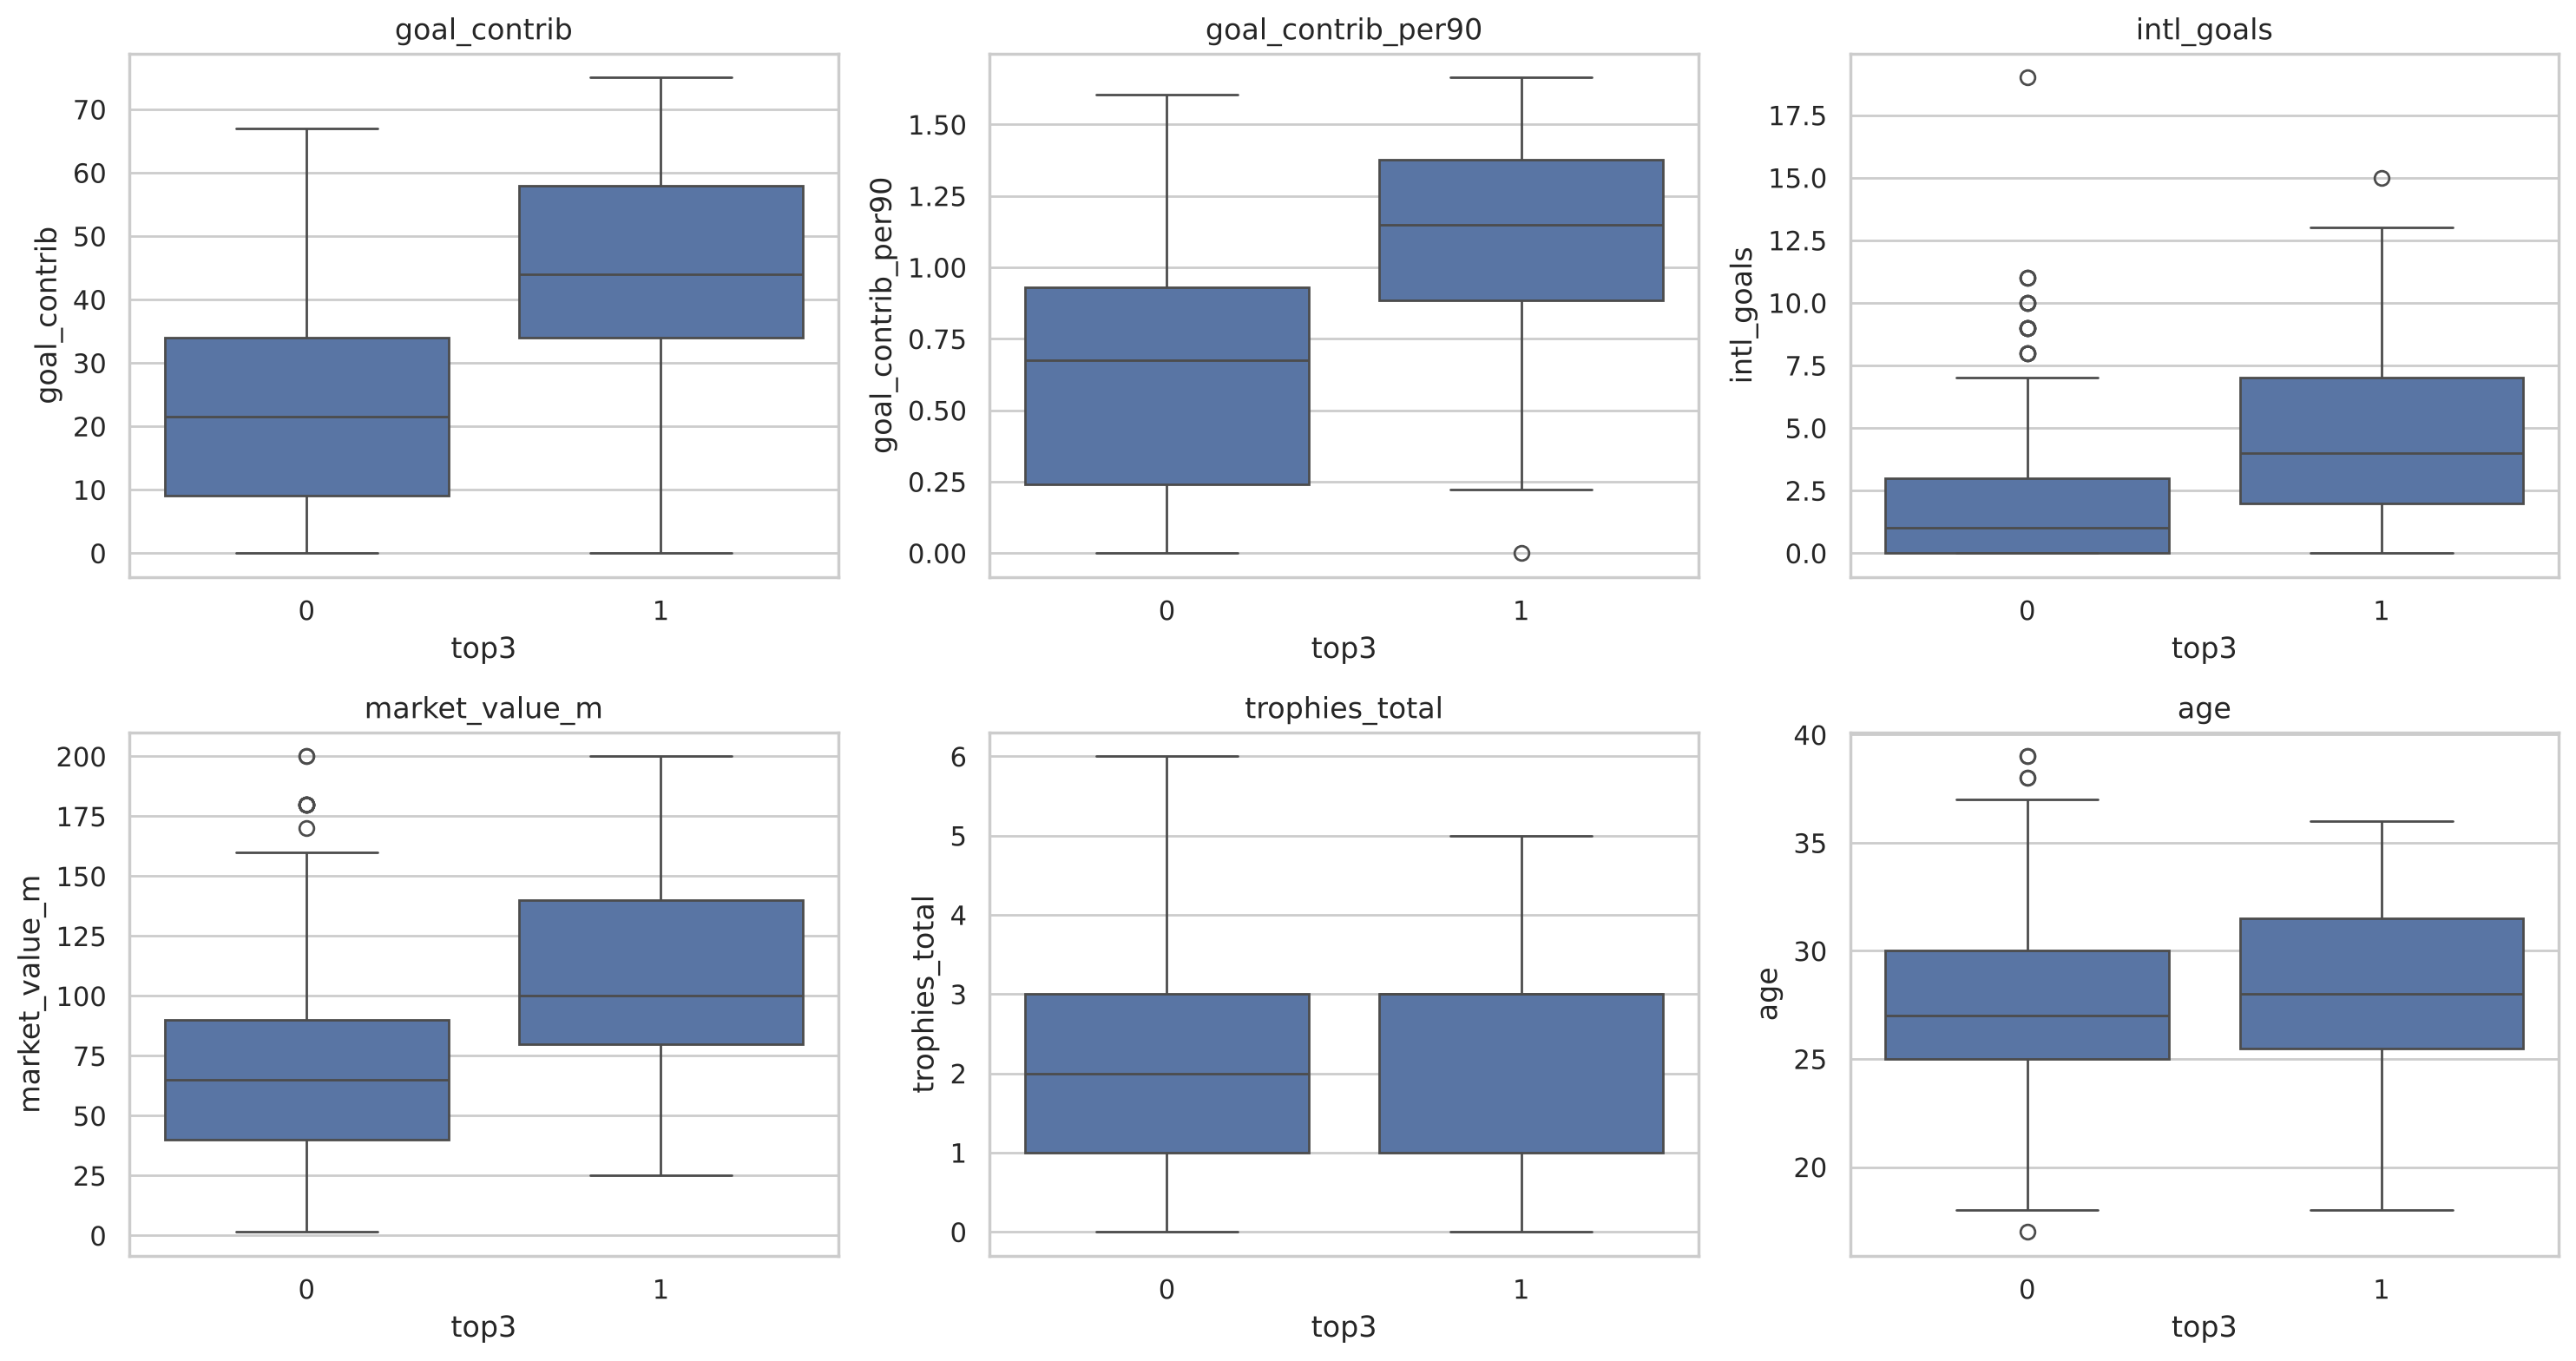

In [15]:
key_num = ["goal_contrib", "goal_contrib_per90", "intl_goals", "market_value_m",
           "trophies_total", "age"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_num):
    sns.boxplot(data=data, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 6. Categorical variables

For a categorical variable, the natural summary is the **podium rate per category**.

In [16]:
def podium_rate(col):
    """Podium rate and number of rows for each value of a column."""
    return (data.groupby(col)[TARGET].agg(podium_rate="mean", n="size")
            .sort_values("podium_rate", ascending=False))

podium_rate("position")

,podium_rate,n
position,,
forward,0.163,178
midfielder,0.071,112
goalkeeper,0.038,26
defender,0.019,53


In [17]:
# Stage reached in the Champions League (0 = absent ... 6 = winner)
podium_rate("ucl_stage").sort_index()

,podium_rate,n
ucl_stage,,
0.000,0.000,35
1.000,0.125,8
2.000,0.029,35
3.000,0.157,51
4.000,0.151,53
5.000,0.038,26
6.000,0.188,85


In [18]:
# Stage reached with the national team in a tournament
podium_rate("intl_stage").sort_index()

,podium_rate,n
intl_stage,,
0.000,0.089,180
1.000,0.154,13
2.000,0.037,27
3.000,0.032,31
4.000,0.083,24
5.000,0.174,23
6.000,0.180,50


In [19]:
# Big titles: Champions League and/or major national-team trophy
podium_rate(["won_ucl", "won_major_intl"])

podium_rate    n
won_ucl won_major_intl                  
1       0                     0.189   74
        1                     0.182   11
0       1                     0.179   39
        0                     0.065  245

In [20]:
# Clubs with at least 10 ranked players
club_rates = data.groupby("club")[TARGET].agg(podium_rate="mean", n="size")
club_rates.query("n >= 10").sort_values("podium_rate", ascending=False)

,podium_rate,n
club,,
Barcelona,0.243,37
Atlético Madrid,0.182,11
Real Madrid,0.172,58
Juventus,0.133,15
Paris Saint-Germain,0.128,39
Bayern Munich,0.114,35
Liverpool,0.080,25
Manchester City,0.077,39
Chelsea,0.056,18


## 7. Feature importance

### 7.1 Correlation with the target

The correlation between a numeric feature and a 0/1 target (point-biserial correlation) tells
how much the feature moves with the podium. It only captures **linear** relationships.

In [21]:
features = [c for c in data.select_dtypes("number").columns
            if c not in LEAKAGE + IDENTIFIERS + [TARGET, "year", "season_based", "stats_complete"]]

corr = data[features + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
corr.tail(15)

ranked_prev               0.252
intl_major_goals          0.257
intl_goals                0.260
market_value_eur          0.279
market_value_m            0.279
market_value_m_pct_year   0.280
goal_contrib_per90        0.316
goal_contrib_pct_year     0.319
goals_per90               0.326
prev_top3                 0.341
league_goals              0.343
goal_contrib              0.379
goals                     0.384
ucl_goals                 0.415
europe_goals              0.417
Name: top3, dtype: float64

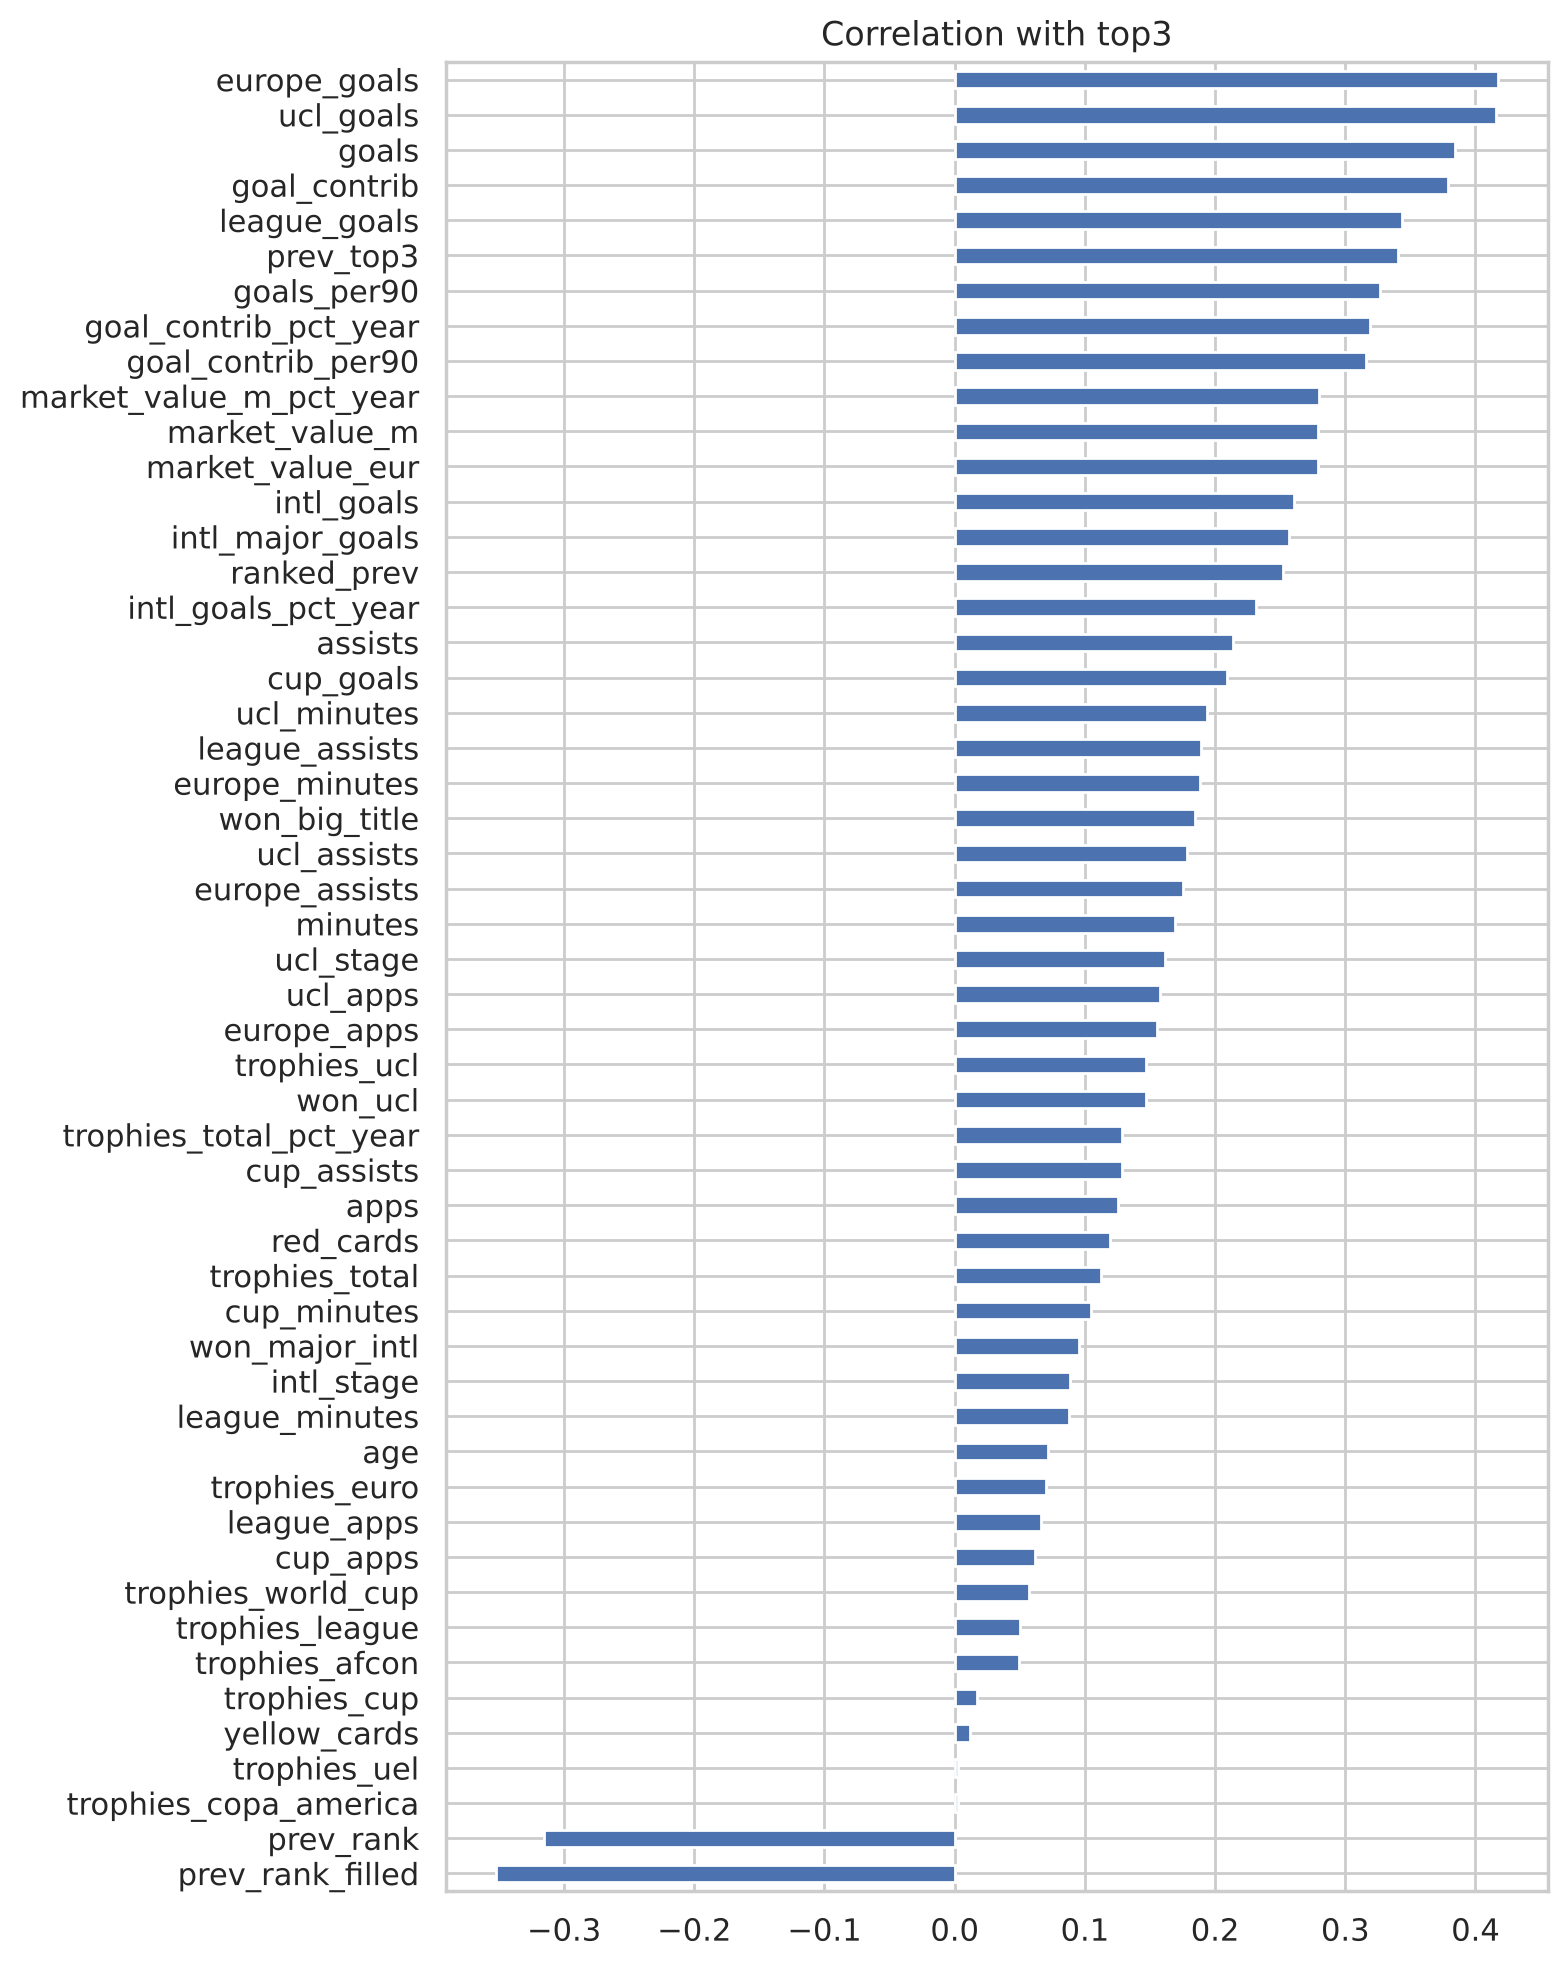

In [22]:
fig, ax = plt.subplots(figsize=(8, 10))
corr.plot.barh(ax=ax)
ax.set_title("Correlation with top3")
plt.tight_layout()
plt.show()

### 7.2 Mutual information

Mutual information measures any kind of dependence (not only linear). It needs a table
without missing values, so we fill the gaps with the median, just for this analysis.

In [23]:
X = data[features].fillna(data[features].median())
mi = mutual_info_classif(X, data[TARGET], random_state=42)
mi = pd.Series(mi, index=features).sort_values(ascending=False)
mi.head(15)

prev_rank_filled          0.091
prev_rank                 0.084
goals                     0.080
ucl_goals                 0.076
europe_goals              0.072
goal_contrib_per90        0.067
goal_contrib              0.066
market_value_m_pct_year   0.062
goal_contrib_pct_year     0.059
league_goals              0.053
league_assists            0.050
goals_per90               0.049
minutes                   0.046
cup_minutes               0.032
ucl_stage                 0.031
dtype: float64

### 7.3 Correlations between the strongest features

Many features say almost the same thing (`goals`, `league_goals`, `goal_contrib`...). The
heatmap shows these redundancies, which matter for the linear model.

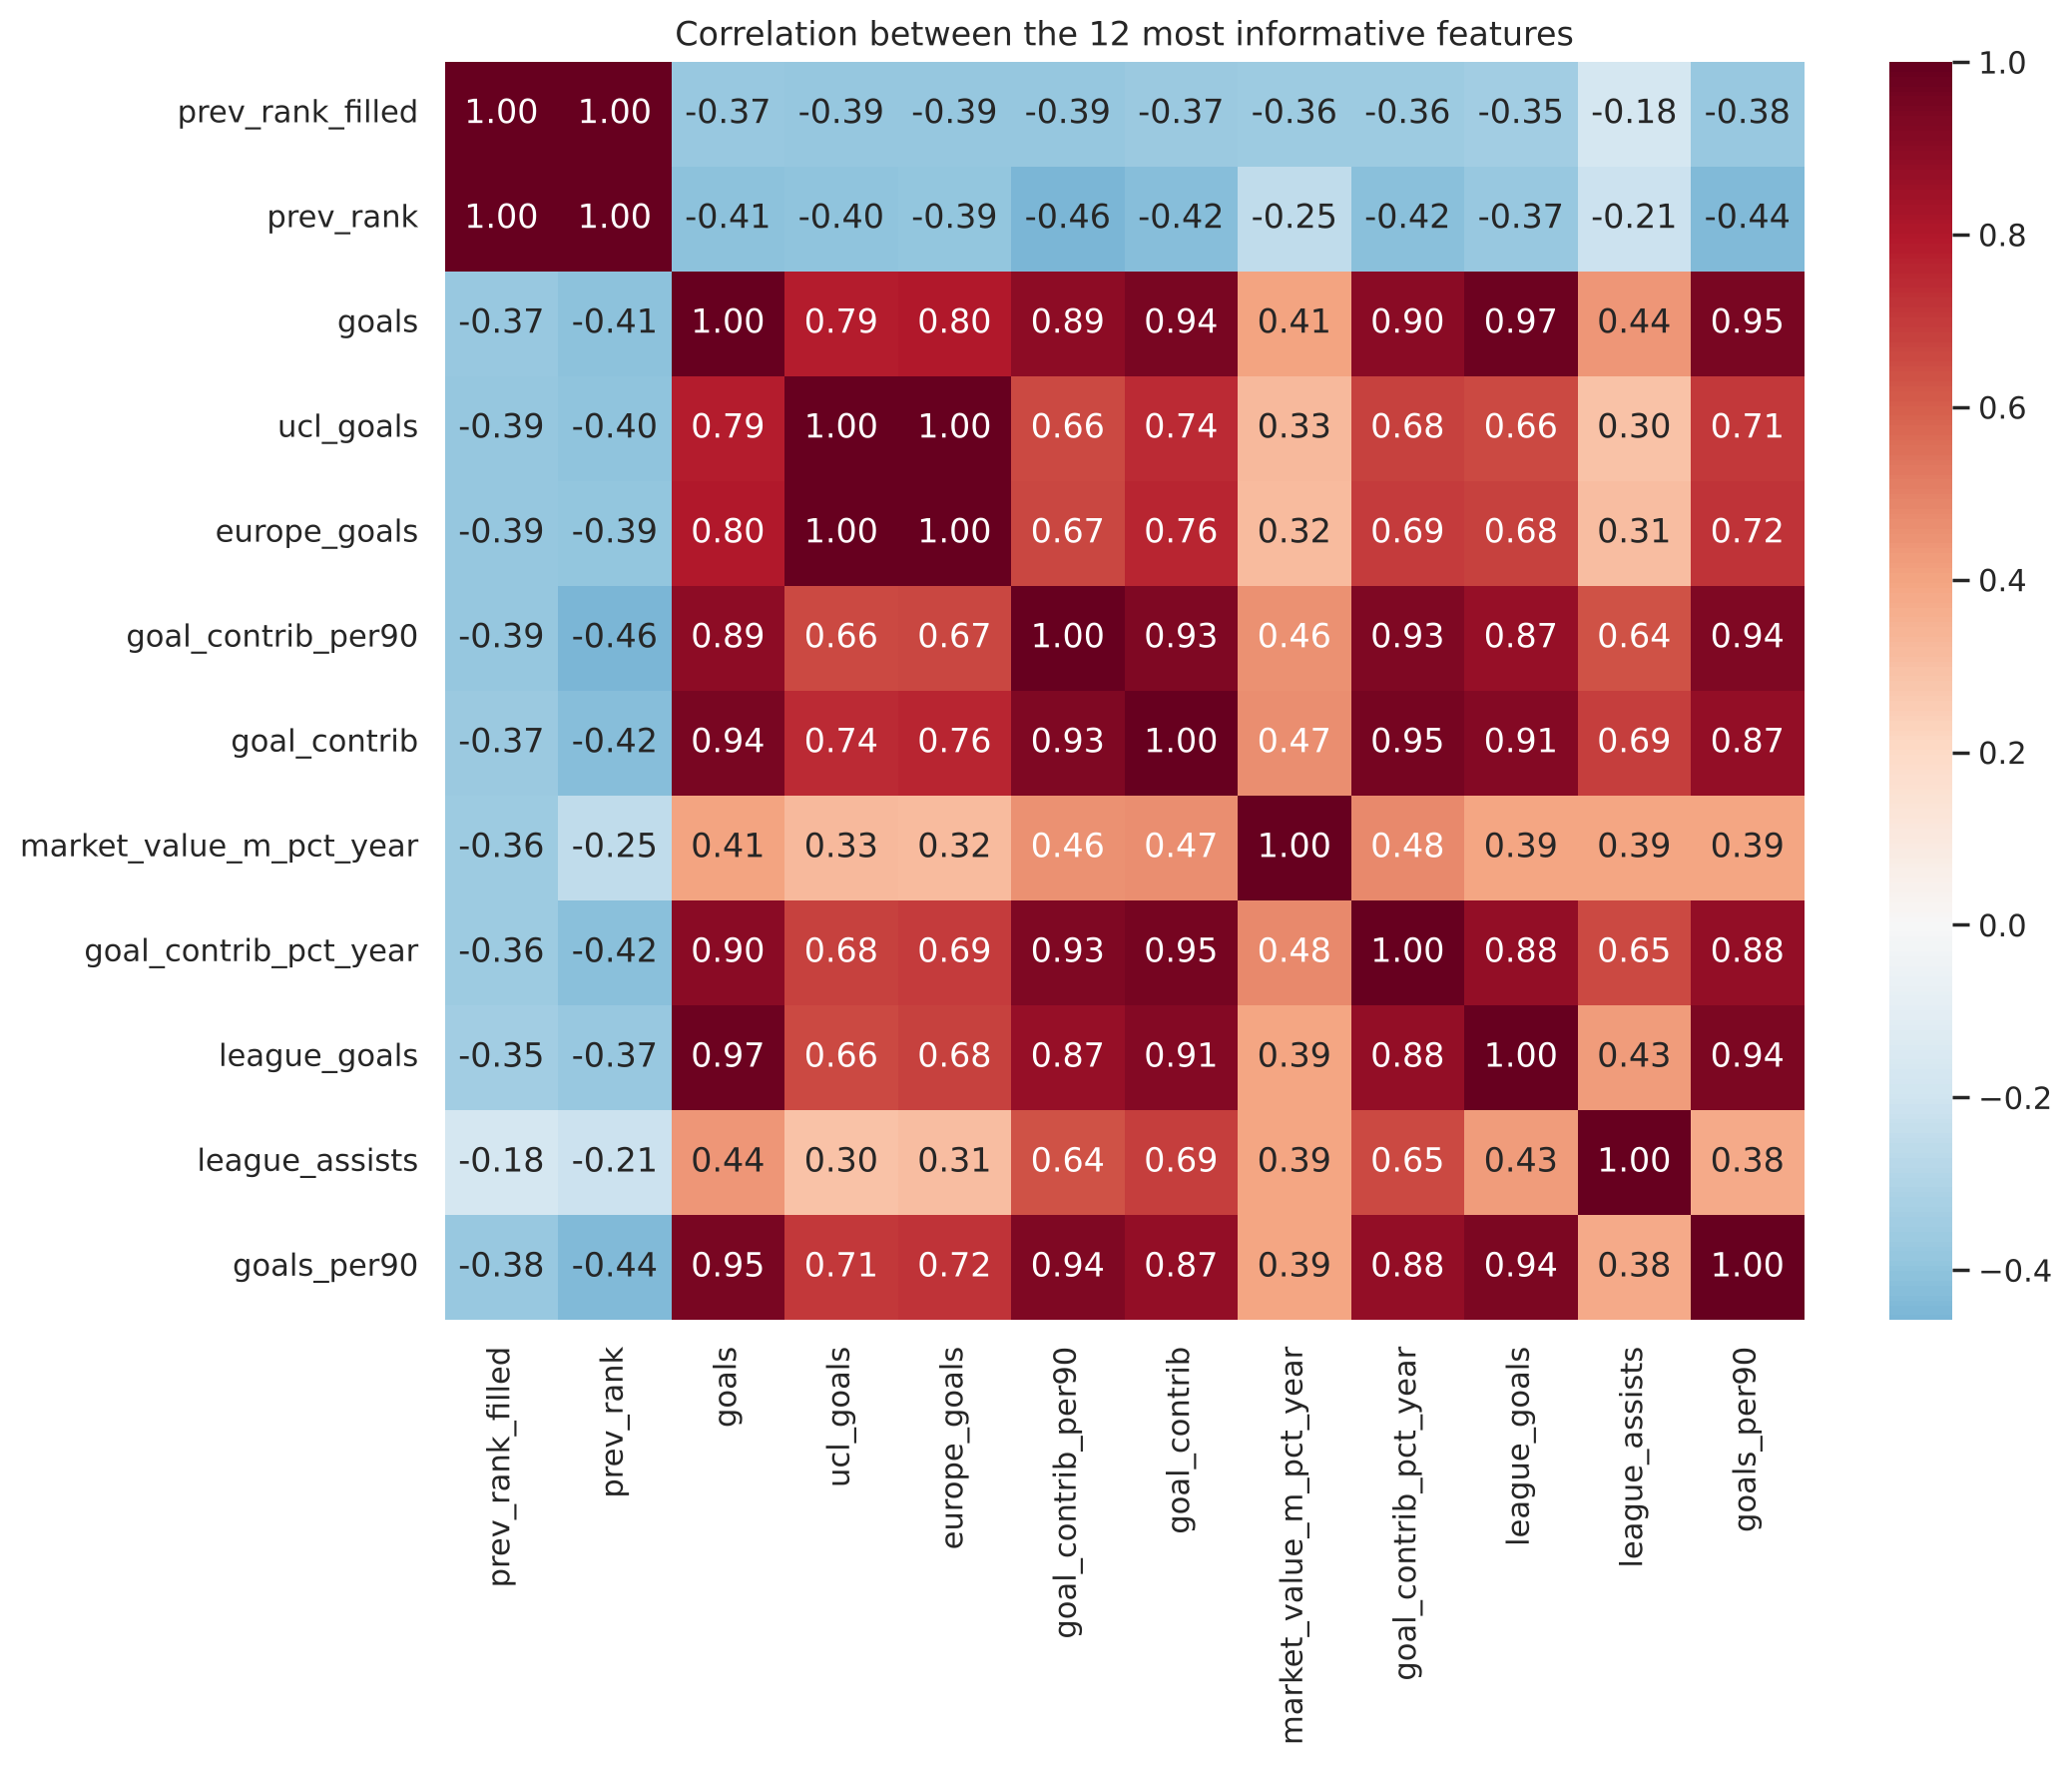

In [24]:
top_features = mi.head(12).index.tolist()
plt.figure(figsize=(11, 9))
sns.heatmap(data[top_features].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation between the 12 most informative features")
plt.tight_layout()
plt.show()

## 8. Focus: the winners and the 2026 edition

In [25]:
winner_cols = ["year", "name", "position", "club", "goal_contrib", "intl_goals",
               "market_value_m", "won_ucl", "won_major_intl", "prev_rank"]
data.loc[data["winner"] == 1, winner_cols]

,year,name,position,club,goal_contrib,intl_goals,market_value_m,won_ucl,won_major_intl,prev_rank
0,2013,Cristiano Ronaldo,forward,Real Madrid,73.000,7.000,100.000,0,0,2.000
23,2014,Cristiano Ronaldo,forward,Real Madrid,75.000,3.000,120.000,1,0,1.000
46,2015,Lionel Messi,forward,Barcelona,73.000,1.000,120.000,1,0,2.000
69,2016,Cristiano Ronaldo,forward,Real Madrid,46.000,8.000,110.000,1,1,2.000
99,2017,Cristiano Ronaldo,forward,Real Madrid,42.000,8.000,100.000,1,0,1.000
129,2018,Luka Modrić,midfielder,Real Madrid,9.000,2.000,25.000,1,0,5.000
159,2019,Lionel Messi,forward,Barcelona,49.000,1.000,150.000,0,0,5.000
189,2021,Lionel Messi,forward,Paris Saint-Germain,40.000,9.000,80.000,0,1,1.000
219,2022,Karim Benzema,forward,Real Madrid,59.000,6.000,30.000,1,0,4.000
249,2023,Lionel Messi,forward,Inter Miami,40.000,7.000,35.000,0,1,NaN


In [26]:
# 2026 podium compared with the rest of the 2026 top 10
cols_2026 = ["rank", "name", "goal_contrib", "intl_goals", "intl_major_goals",
             "market_value_m", "trophies_total", "ucl_stage", "intl_stage", "prev_rank"]
data.query("year == 2026").sort_values("rank")[cols_2026].head(10)

,rank,name,goal_contrib,intl_goals,intl_major_goals,market_value_m,trophies_total,ucl_stage,intl_stage,prev_rank
339,1,Harry Kane,65.000,11.000,6.000,60.000,3.000,4.000,4.000,13.000
340,2,Kylian Mbappé,49.000,15.000,10.000,180.000,0.000,3.000,4.000,7.000
341,3,Lamine Yamal,42.000,1.000,1.000,200.000,3.000,3.000,6.000,2.000
342,4,Rodri,2.000,0.000,0.000,50.000,3.000,NaN,6.000,NaN
343,5,Lionel Messi,NaN,10.000,8.000,15.000,1.000,NaN,5.000,NaN
344,6,Khvicha Kvaratskhelia,28.000,2.000,0.000,140.000,5.000,6.000,0.000,12.000
345,7,Ousmane Dembélé,28.000,6.000,6.000,100.000,5.000,6.000,4.000,1.000
346,8,Erling Haaland,46.000,19.000,7.000,200.000,2.000,2.000,3.000,26.000
347,9,Michael Olise,52.000,2.000,0.000,150.000,3.000,4.000,4.000,30.000
348,10,Fabián Ruiz,7.000,1.000,1.000,30.000,6.000,6.000,6.000,24.000


## 9. Summary of the EDA

**Target.** 39 podium rows out of 369 (≈ 11 %): imbalanced classes → ROC AUC rather than accuracy.

**What separates the podium from the rest** (means and medians, section 5):
- **Past reputation is the strongest single signal.** 36 % of podium players were already on
  the podium the year before, against 5 % for the others. The jury has a memory.
- **Scoring, above all in Europe.** Median of 32 goals for podium players against 11. Goals in
  European competitions (`europe_goals`, `ucl_goals`) are the most correlated stats (≈ 0.42):
  big nights in the Champions League weigh more than league goals.
- **National-team tournaments.** Podium players score almost 3 times more goals in major
  tournaments (`intl_major_goals`) — confirming that national-team stats must be kept.
- **Big titles.** Winning the Champions League or a major national trophy triples the podium
  rate (≈ 18 % vs 6.5 %).
- **Market value** helps, moderately (median 100 M€ vs 65 M€). **Age** barely matters.

**Categorical variables** (section 6):
- **Position matters a lot**: 16 % podium rate for forwards, 7 % for midfielders, 2–4 % for
  defenders and goalkeepers.
- **Stages are not monotonic**: reaching the Champions League final and **losing** it (stage 5)
  gives a lower podium rate than a semi-final. Treat stages as categories, not as numbers.

**Feature importance** (section 7): correlation and mutual information agree on the top
features — previous rank, (European) goals, goal contributions per 90, market value. Many stat
columns are highly redundant: the linear model will need regularisation or a reduced set.

**Limits to keep in mind**
- Some winners are not explained by statistics: **Modrić 2018** (9 goals + assists) or
  **Rodri 2024** won through their role and trophies. A stats-based model will miss them.
- Small dataset (369 rows, 39 positives): use a **time-based split** (train on past editions,
  validate on recent ones) and keep the model simple.

# Part 2 — Model training and selection

## 10. Modelling setup

### 10.1 One function for all the data preparation

The EDA steps (missing values, new features) are gathered in a single function. The same
function will be reused in `train.py` and `predict.py`, so that the model always receives
data prepared in exactly the same way.

Choices made after the EDA:
- **Stages become categories** (`"s0"` … `"s6"`, `"unknown"`), since they are not monotonic.
- **Missing club stats are set to 0**: the model is told about it through `stats_complete`.

In [27]:
from itertools import product
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

NUMERICAL = [
    "age", "minutes", "goals", "assists", "goal_contrib", "goal_contrib_per90",
    "europe_goals", "ucl_goals", "league_goals", "intl_goals", "intl_major_goals",
    "market_value_m", "trophies_total", "won_ucl", "won_major_intl",
    "ranked_prev", "prev_rank_filled", "prev_top3",
    "goal_contrib_pct_year", "intl_goals_pct_year", "market_value_m_pct_year",
    "trophies_total_pct_year", "stats_complete", "season_based",
]
CATEGORICAL = ["position", "ucl_stage", "intl_stage"]


def prepare_features(df):
    """Cleaning + feature engineering, identical to sections 3.2-3.4."""
    d = df.copy()
    d["ranked_prev"] = d["prev_rank"].notna().astype(int)
    d["prev_rank_filled"] = d["prev_rank"].fillna(31)
    d["prev_top3"] = (d["prev_rank_filled"] <= 3).astype(int)

    trophy_cols = [c for c in d.columns if c.startswith("trophies_")]
    d[trophy_cols] = d[trophy_cols].fillna(0)

    d["goal_contrib"] = d["goals"] + d["assists"]
    per90 = 90 / d["minutes"].where(d["minutes"] > 0)
    d["goal_contrib_per90"] = d["goal_contrib"] * per90
    d["market_value_m"] = d["market_value_eur"] / 1e6
    d["won_ucl"] = (d["trophies_ucl"] > 0).astype(int)
    d["won_major_intl"] = (d[["trophies_world_cup", "trophies_euro", "trophies_copa_america",
                              "trophies_afcon"]].sum(axis=1) > 0).astype(int)

    for col in ["goal_contrib", "intl_goals", "market_value_m", "trophies_total"]:
        d[f"{col}_pct_year"] = d.groupby("year")[col].rank(pct=True)

    # Stages are treated as categories (see section 6)
    for col in ["ucl_stage", "intl_stage"]:
        d[col] = d[col].map(lambda v: "unknown" if pd.isna(v) else f"s{int(v)}")
    return d


def to_records(d):
    """Feature table -> list of dicts, the input format of DictVectorizer."""
    x = d[NUMERICAL + CATEGORICAL].copy()
    x[NUMERICAL] = x[NUMERICAL].fillna(0)
    return x.to_dict(orient="records")


prepared = prepare_features(df)

### 10.2 Splitting by year, not at random

A random split would put players of the **same edition** in both train and validation sets:
the model would learn the 2018 vote and be tested on the 2018 vote. Instead we split by time:

| Set | Editions | Use |
|---|---|---|
| Development | 2013–2024 (11 editions) | training + tuning by cross-validation |
| Test | 2025–2026 | final, untouched evaluation |

On the development set we use **leave-one-year-out cross-validation**: for each of the 11
editions, train on the 10 others and predict the left-out one. Every player is predicted
exactly once, by a model that never saw his edition.

In [28]:
dev = prepared[prepared["year"] <= 2024]
test = prepared[prepared["year"] >= 2025]
dev_years = sorted(dev["year"].unique())
print(f"development: {len(dev)} rows, {dev[TARGET].sum()} podium | "
      f"test: {len(test)} rows, {test[TARGET].sum()} podium")

development: 309 rows, 33 podium | test: 60 rows, 6 podium


### 10.3 Metrics

- **ROC AUC**: probability that a random podium player gets a higher score than a random
  non-podium player (0.5 = random, 1 = perfect). Robust to class imbalance.
- **Podium hit rate**: for each edition, take the 3 players with the highest predicted
  probability and count how many really finished in the top 3. This is the metric that
  matches the real question.

In [29]:
def podium_hit_rate(d, scores):
    """Share of the real podium found among the 3 best predicted players of each year."""
    d = d.assign(score=np.asarray(scores))
    hits = d.groupby("year").apply(lambda g: g.nlargest(3, "score")[TARGET].sum(),
                                   include_groups=False)
    return hits.sum() / (3 * d["year"].nunique())


def cross_validate(make_model):
    """Leave-one-year-out CV on the development set -> (AUC, podium hit rate)."""
    preds = pd.Series(index=dev.index, dtype=float)
    for year in dev_years:
        train_part, valid_part = dev[dev["year"] != year], dev[dev["year"] == year]
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(to_records(train_part))
        X_valid = dv.transform(to_records(valid_part))
        model = make_model()
        model.fit(X_train, train_part[TARGET])
        preds[valid_part.index] = model.predict_proba(X_valid)[:, 1]
    return roc_auc_score(dev[TARGET], preds), podium_hit_rate(dev, preds)

### 10.4 Baseline

Before any model, a naive rule: *"the players ranked best last year will be on the podium"*.
Every model must beat it to be useful.

In [30]:
baseline_scores = -dev["prev_rank_filled"]   # best previous rank = highest score
results = [{"model": "baseline (previous rank)", "params": "-",
            "auc": roc_auc_score(dev[TARGET], baseline_scores),
            "podium_hit_rate": podium_hit_rate(dev, baseline_scores)}]
pd.DataFrame(results)

,model,params,auc,podium_hit_rate
0,baseline (previous rank),-,0.804,0.455


## 11. Logistic regression (linear model)

Features have very different scales (minutes in thousands, flags in 0/1), so they are
standardised first. We tune `C`, the inverse of the regularisation strength: a small `C`
shrinks the coefficients, which helps with the many redundant features seen in section 7.3.

In [31]:
logreg_results = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    auc, hit = cross_validate(lambda: make_pipeline(
        StandardScaler(), LogisticRegression(C=C, max_iter=5000)))
    logreg_results.append({"model": "logistic regression", "params": f"C={C}",
                           "auc": auc, "podium_hit_rate": hit})
pd.DataFrame(logreg_results)

,model,params,auc,podium_hit_rate
0,logistic regression,C=0.001,0.868,0.606
1,logistic regression,C=0.01,0.889,0.576
2,logistic regression,C=0.1,0.907,0.576
3,logistic regression,C=1,0.903,0.606
4,logistic regression,C=10,0.892,0.576


## 12. Decision tree

A single tree is easy to read but tends to overfit. We tune its depth (`max_depth`) and the
minimum number of players in a leaf (`min_samples_leaf`).

In [32]:
tree_results = []
for depth, leaf in product([2, 3, 4, 6, None], [1, 5, 10]):
    auc, hit = cross_validate(lambda: DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=leaf, random_state=1))
    tree_results.append({"model": "decision tree", "params": f"max_depth={depth}, leaf={leaf}",
                         "auc": auc, "podium_hit_rate": hit})
pd.DataFrame(tree_results).sort_values("auc", ascending=False).head(5)

,model,params,auc,podium_hit_rate
13,decision tree,"max_depth=None, leaf=5",0.764,0.394
10,decision tree,"max_depth=6, leaf=5",0.756,0.455
11,decision tree,"max_depth=6, leaf=10",0.744,0.394
14,decision tree,"max_depth=None, leaf=10",0.737,0.424
5,decision tree,"max_depth=3, leaf=10",0.724,0.455


## 13. Gradient boosting (XGBoost)

Trees built one after another, each correcting the errors of the previous ones. We tune the
learning rate `eta`, the tree depth and the number of trees.

In [33]:
xgb_results = []
for eta, depth, n_trees in product([0.05, 0.1, 0.3], [2, 3, 4], [100, 300]):
    auc, hit = cross_validate(lambda: XGBClassifier(
        learning_rate=eta, max_depth=depth, n_estimators=n_trees, subsample=0.8,
        eval_metric="logloss", random_state=1, verbosity=0))
    xgb_results.append({"model": "xgboost", "params": f"eta={eta}, max_depth={depth}, n={n_trees}",
                        "auc": auc, "podium_hit_rate": hit})
pd.DataFrame(xgb_results).sort_values("auc", ascending=False).head(5)

,model,params,auc,podium_hit_rate
1,xgboost,"eta=0.05, max_depth=2, n=300",0.860,0.485
6,xgboost,"eta=0.1, max_depth=2, n=100",0.860,0.485
7,xgboost,"eta=0.1, max_depth=2, n=300",0.856,0.515
0,xgboost,"eta=0.05, max_depth=2, n=100",0.851,0.485
8,xgboost,"eta=0.1, max_depth=3, n=100",0.849,0.485


## 14. Random forest

Many trees trained on random subsets of rows and features, then averaged. We tune:
- `max_depth`: depth of each tree;
- `min_samples_leaf`: size of the leaves (larger = smoother model);
- `max_features`: share of features tried at each split (lower = more diverse trees).

The number of trees is fixed at 300: beyond a few hundred, more trees only cost time.

In [34]:
rf_results = []
for depth, leaf, max_feat in product([4, 8, None], [1, 5, 10], ["sqrt", 0.5]):
    auc, hit = cross_validate(lambda: RandomForestClassifier(
        n_estimators=300, max_depth=depth, min_samples_leaf=leaf, max_features=max_feat,
        random_state=1, n_jobs=-1))
    rf_results.append({"model": "random forest",
                       "params": f"max_depth={depth}, leaf={leaf}, max_features={max_feat}",
                       "auc": auc, "podium_hit_rate": hit})
pd.DataFrame(rf_results).sort_values("auc", ascending=False).head(5)

,model,params,auc,podium_hit_rate
10,random forest,"max_depth=8, leaf=10, max_features=sqrt",0.838,0.545
16,random forest,"max_depth=None, leaf=10, max_features=sqrt",0.838,0.545
4,random forest,"max_depth=4, leaf=10, max_features=sqrt",0.835,0.515
6,random forest,"max_depth=8, leaf=1, max_features=sqrt",0.829,0.545
14,random forest,"max_depth=None, leaf=5, max_features=sqrt",0.828,0.515


## 15. Model comparison

Best setting of each family, on the development set (leave-one-year-out CV).

In [35]:
all_results = pd.DataFrame(results + logreg_results + tree_results + xgb_results + rf_results)
best = (all_results.sort_values("auc", ascending=False)
        .groupby("model").head(1).reset_index(drop=True))
best

,model,params,auc,podium_hit_rate
0,logistic regression,C=0.1,0.907,0.576
1,xgboost,"eta=0.05, max_depth=2, n=300",0.860,0.485
2,random forest,"max_depth=8, leaf=10, max_features=sqrt",0.838,0.545
3,baseline (previous rank),-,0.804,0.455
4,decision tree,"max_depth=None, leaf=5",0.764,0.394


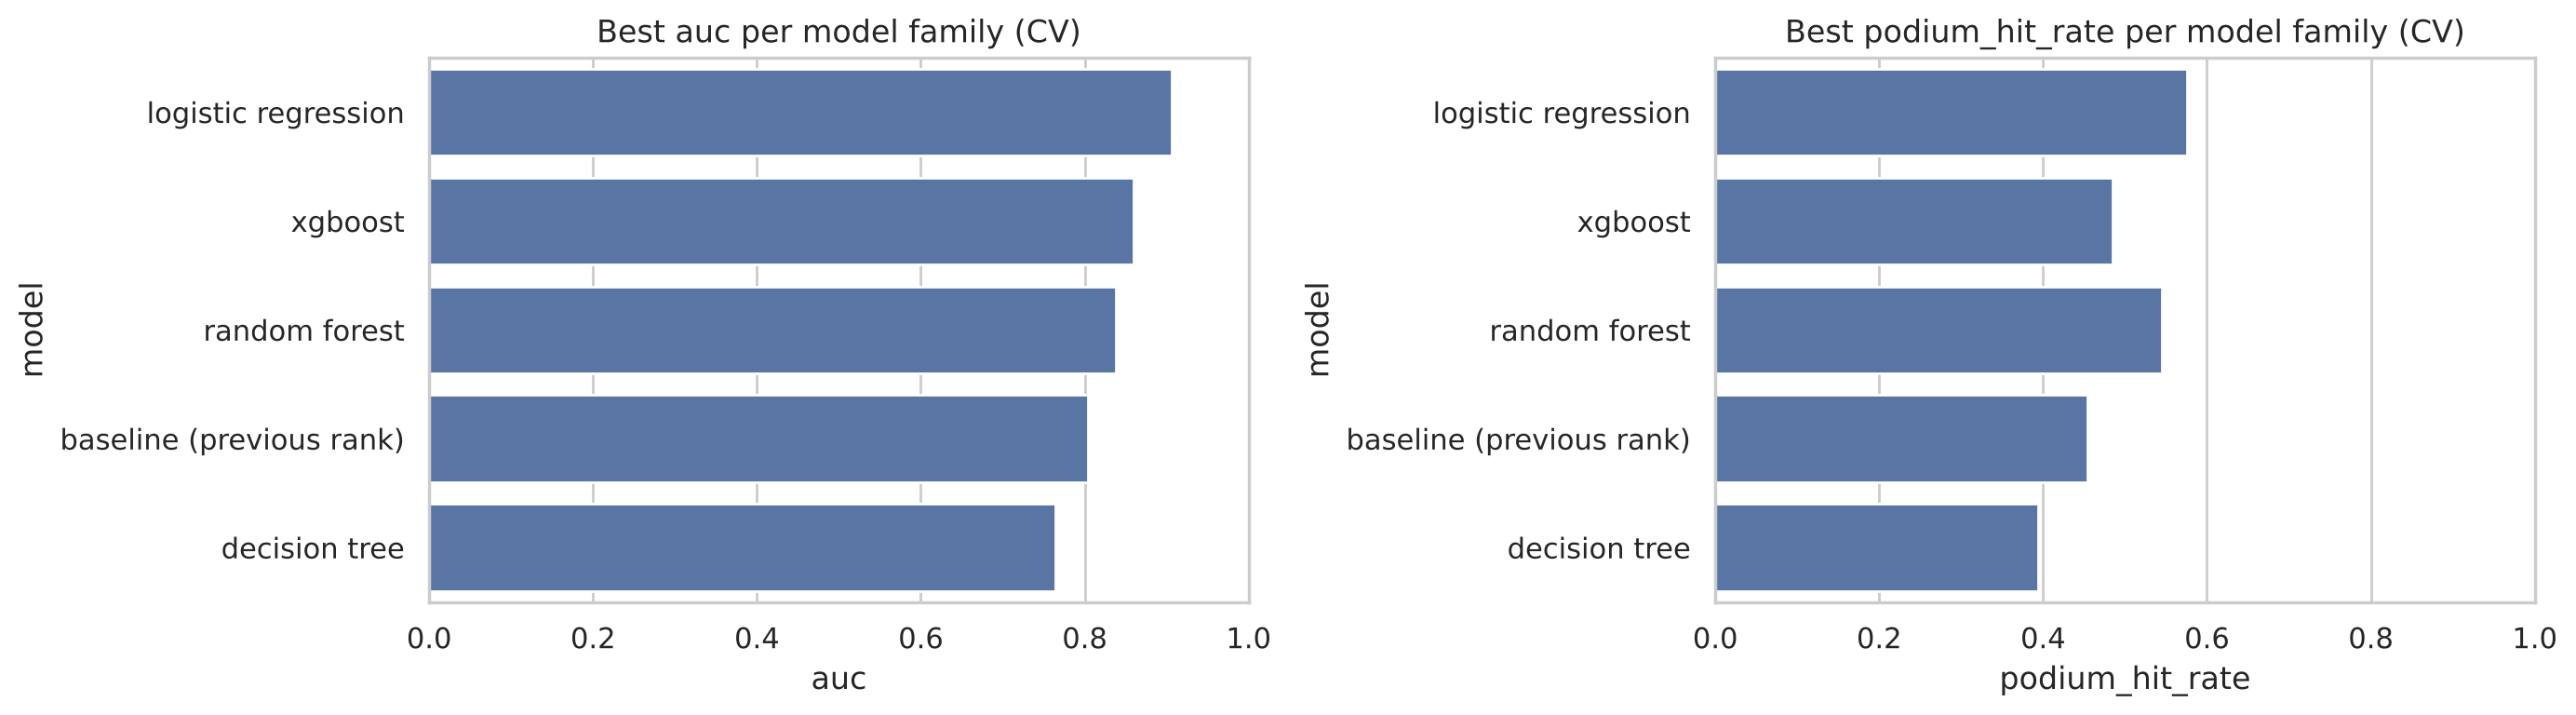

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ["auc", "podium_hit_rate"]):
    sns.barplot(data=best, y="model", x=metric, ax=ax)
    ax.set_xlim(0, 1)
    ax.set_title(f"Best {metric} per model family (CV)")
plt.tight_layout()
plt.show()

**Reading the comparison**
- Every tuned model except the single decision tree beats the baseline (AUC 0.80): the
  season's statistics add information on top of last year's rank.
- **Logistic regression is the best model in cross-validation** (AUC 0.91, 58 % of podium
  places found), ahead of XGBoost (0.86) and the random forest (0.84). With only 309 rows and
  33 positives, a simple regularised linear model generalises better than flexible trees.
- Tuning matters: the best settings are the most constrained ones (`C=0.1`, shallow boosted
  trees with `max_depth=2`, forest leaves of at least 10 players) - a sign that overfitting is
  the main risk on this small dataset.
- The single decision tree is below the baseline: too unstable with so little data.

## 16. Final model: evaluation on the untouched test set (2025–2026)

We retrain the selected models on the whole development set (2013–2024) and evaluate them
**once** on 2025–2026: the logistic regression (best in cross-validation) and the tuned
random forest.

In [37]:
FINAL_MODELS = {
    "logistic regression (C=0.1)": lambda: make_pipeline(
        StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)),
    "random forest (tuned)": lambda: RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=10, max_features="sqrt",
        random_state=1, n_jobs=-1),
}

dv = DictVectorizer(sparse=False)
X_dev = dv.fit_transform(to_records(dev))
X_test = dv.transform(to_records(test))

fitted, test_scores = {}, {}
for name, make_model in FINAL_MODELS.items():
    model = make_model().fit(X_dev, dev[TARGET])
    fitted[name] = model
    test_scores[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:30s} test AUC = {roc_auc_score(test[TARGET], test_scores[name]):.3f} | "
          f"podium hit rate = {podium_hit_rate(test, test_scores[name]):.0%}")

logistic regression (C=0.1)    test AUC = 0.849 | podium hit rate = 33%


random forest (tuned)          test AUC = 0.836 | podium hit rate = 33%


In [38]:
# Predicted top 5 of each test edition, for both models (rank = real final rank)
for name, scores in test_scores.items():
    view = test.assign(prob_top3=scores)
    for year, g in view.groupby("year"):
        print(f"\n=== {name} | {year} ===")
        print(g.nlargest(5, "prob_top3")[["name", "rank", "prob_top3"]].to_string(index=False))


=== logistic regression (C=0.1) | 2025 ===
           name  rank  prob_top3
 Erling Haaland    26      0.556
     Harry Kane    13      0.303
Vinícius Júnior    16      0.271
       Raphinha     5      0.262
  Kylian Mbappé     7      0.257

=== logistic regression (C=0.1) | 2026 ===
           name  rank  prob_top3
  Kylian Mbappé     2      0.946
     Harry Kane     1      0.802
 Erling Haaland     8      0.613
Ousmane Dembélé     7      0.526
   Lamine Yamal     3      0.514

=== random forest (tuned) | 2025 ===
           name  rank  prob_top3
Viktor Gyökeres    15      0.388
     Harry Kane    13      0.351
  Kylian Mbappé     7      0.347
       Raphinha     5      0.271
 Erling Haaland    26      0.261

=== random forest (tuned) | 2026 ===
           name  rank  prob_top3
     Harry Kane     1      0.471
  Kylian Mbappé     2      0.458
 Erling Haaland     8      0.359
   Lamine Yamal     3      0.356
Ousmane Dembélé     7      0.312


### What drives the models?

**Logistic regression.** Features are standardised, so coefficients can be compared: a positive
coefficient pushes towards the podium, a negative one away from it.

In [39]:
logreg_name, rf_name = list(FINAL_MODELS)
coefs = pd.Series(fitted[logreg_name][-1].coef_[0], index=dv.get_feature_names_out())
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12)

age                        0.453
intl_major_goals           0.382
prev_rank_filled          -0.359
market_value_m             0.323
won_major_intl             0.292
intl_stage=s6              0.292
market_value_m_pct_year    0.284
ucl_stage=s6               0.280
won_ucl                    0.280
position=forward          -0.268
ucl_stage=s2              -0.261
minutes                    0.241
dtype: float64

**Random forest.** `feature_importances_` measures how much each feature reduces impurity
across all the trees (always positive: it gives the weight, not the direction).

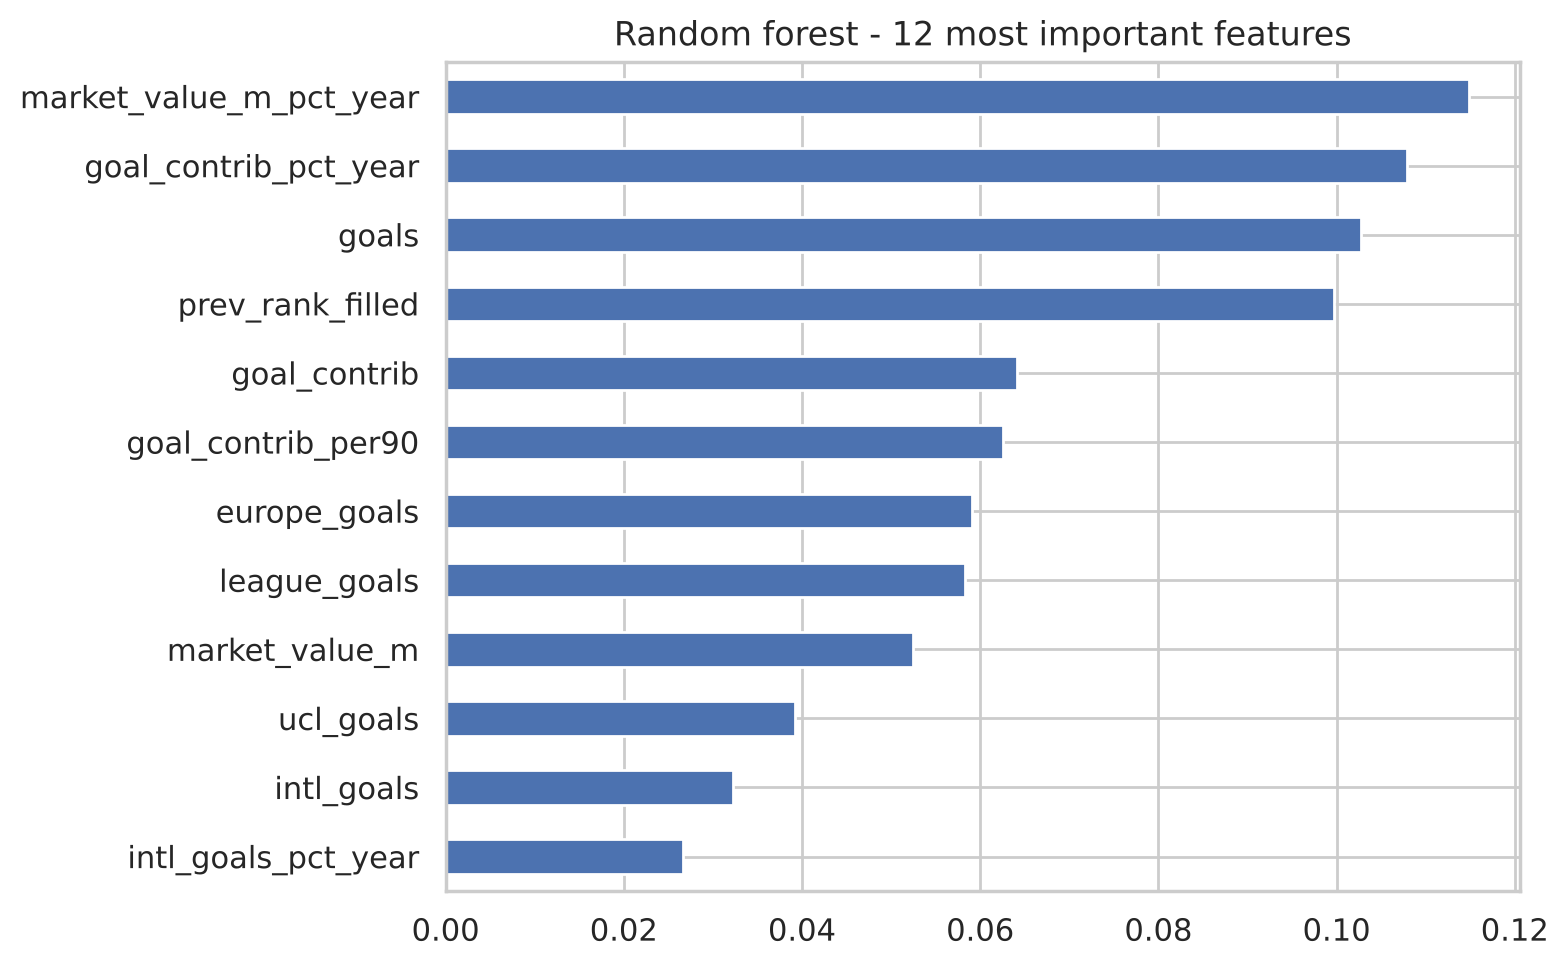

market_value_m_pct_year   0.115
goal_contrib_pct_year     0.108
goals                     0.103
prev_rank_filled          0.100
goal_contrib              0.064
goal_contrib_per90        0.063
europe_goals              0.059
league_goals              0.058
market_value_m            0.052
ucl_goals                 0.039
intl_goals                0.032
intl_goals_pct_year       0.027
dtype: float64

In [40]:
importances = pd.Series(fitted[rf_name].feature_importances_, index=dv.get_feature_names_out())
importances.sort_values(ascending=False).head(12).plot.barh(figsize=(8, 5)).invert_yaxis()
plt.title("Random forest - 12 most important features")
plt.tight_layout()
plt.show()
importances.sort_values(ascending=False).head(12)

## 17. Simplified final model: one player at a time

Four features (`*_pct_year`) compare a player with the other nominees of his edition. They
force the web service to receive a whole edition at once. Do we need them? We rerun the
selected model without them.

In [41]:
NUMERICAL_FULL = NUMERICAL
NUMERICAL = [c for c in NUMERICAL_FULL if not c.endswith("_pct_year")]   # used by to_records

make_logreg = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
auc_cv, hit_cv = cross_validate(make_logreg)

dv_simple = DictVectorizer(sparse=False)
simple_model = make_logreg().fit(dv_simple.fit_transform(to_records(dev)), dev[TARGET])
auc_test = roc_auc_score(test[TARGET],
                         simple_model.predict_proba(dv_simple.transform(to_records(test)))[:, 1])

NUMERICAL = NUMERICAL_FULL   # restore the full list
full = best[best["model"] == "logistic regression"].iloc[0]
pd.DataFrame({
    "with *_pct_year": [full["auc"], full["podium_hit_rate"],
                        roc_auc_score(test[TARGET], test_scores[logreg_name])],
    "without": [auc_cv, hit_cv, auc_test],
}, index=["CV AUC", "CV podium hit rate", "test AUC"])

,with *_pct_year,without
CV AUC,0.907,0.907
CV podium hit rate,0.576,0.576
test AUC,0.849,0.855


The performance is unchanged: the relative features bring nothing to the logistic regression.
**The final model is therefore trained without them** (`features.py`, `train.py`), and the web
service scores **one player at a time**.

Note: the model then answers *"does this season look like a podium season?"*. To name the
podium of an edition, score all the nominees and keep the three highest probabilities.

## 18. Conclusion

| Model | CV AUC (2013–2024) | Test AUC (2025–2026) | Test podium hit rate |
|---|---|---|---|
| Logistic regression (C=0.1) | 0.907 | 0.849 | 2 / 6 |
| Random forest (tuned) | 0.838 | 0.836 | 2 / 6 |

- **Selected model: logistic regression (C=0.1), without the `*_pct_year` features**
  (section 17). It was chosen on cross-validation, the only fair
  basis for selection. The random forest is close on the test set, but the test set has only
  6 podium players: a gap of 0.01 AUC there is noise, not evidence.
- **2026**: both models find Kane and Mbappé; Yamal is 4th–5th. The random forest ranks Kane
  first, the logistic regression ranks Mbappé first.
- **2025**: both models miss the whole podium (Dembélé, Yamal, Vitinha). That vote rewarded
  PSG's collective Champions League win, not individual scoring totals - the limit already
  seen in the EDA with Modrić 2018 and Rodri 2024.
- The two models look at the data differently: the regression weighs titles, tournament
  goals and previous rank; the forest relies mostly on goals and market value relative to
  the other nominees of the year.

The training of this model is exported to `train.py`; `predict.py` serves it as a web service.